# Permanencia y promoción en el SNII por sexo, 2023–2025

El SNII no publica quién solicita ingreso, permanencia o promoción ni quién es rechazado: solo el padrón de quienes tienen nombramiento vigente. Pero el padrón dice **cuándo vence** la vigencia de cada persona. Quien vence el 31 de diciembre del año *t* tuvo que pasar por la convocatoria de ese año, y el padrón de *t + 1*, enlazado por CVU, dice qué le pasó.

La pregunta: **a igual nivel, área y año, ¿a las mujeres que vencen les va igual que a los hombres?** Es la parte de la evaluación que sí se puede medir con datos públicos. El ingreso de personas nuevas no se puede medir así, porque no hay lista de solicitantes rechazados.

Datos: padrones oficiales 2023, 2024 y 2025 (`datasets/`). Código: `permanencia/permanencia.py`.

In [1]:
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import permanencia as P
warnings.simplefilter("ignore")
pd.set_option("display.width", 92); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "font.size": 9})
COLOR = {"M": "#2ca25f", "H": "#8856a7"}; GRIS, OSCURO = "#8a8a86", "#3d3d3a"
padrones, sx, d = P.cargar()
ev, v = P.evaluables(d), P.vencian(d)

## Método

- **Cohortes:** personas del padrón de 2023 con vigencia que termina en 2023, y del padrón de 2024 con vigencia que termina en 2024. Niveles Candidatura, I, II y III; se excluye a quien ya era emérito.
- **Resultado**, según el padrón del año siguiente (enlace por CVU, sin ambigüedad de nombres):
  - **promovido:** vigencia nueva (inicia el 1 de enero de *t + 1*) y nivel más alto;
  - **renovado:** vigencia nueva y mismo nivel;
  - **bajó:** vigencia nueva y nivel más bajo;
  - **emérito:** pasó de nivel III a emérito;
  - **no está:** no aparece en el padrón de *t + 1*;
  - **prorrogado:** aparece con la vigencia vieja, extendida (casi siempre 1 o 2 años). No pasó por evaluación;
  - **extensión 15 años:** vigencia vieja con fin a 10 años o más. Tampoco es evaluación.
- **Base de las tasas:** quienes vencían, sin prorrogados ni extensiones (12 841 personas). Las prórrogas se analizan aparte.
- **«Sigue en el SNII»** = renovado, promovido, bajó o emérito. En Candidatura, seguir es lo mismo que ser promovido a nivel I: no hay renovación como candidato.
- **Sexo:** del grado académico del padrón 2023 (DR./DRA., MTRO./MTRA.), enlazado por CVU. Solo 189 personas de las cohortes (1.5 %) no están en el padrón 2023; a ellas se les asigna con el diccionario de nombres (`datasets/mujeres.csv`) y se repite cada estimación sin ellas.
- **Controles:** regresión logística con efectos fijos de nivel, área y año, errores robustos (HC1). Se reporta el efecto marginal promedio de ser mujer en puntos porcentuales (pp), con IC del 95 %.

## Datos

Resultado de todas las personas que vencían, por año de vencimiento.

In [2]:
t = pd.crosstab(v["anio"].rename("vencía en"), v["resultado"])
t = t[["promovido", "renovado", "bajó", "emérito", "no está", "prorrogado", "extensión 15 años"]]
t["total"] = t.sum(axis=1); t

resultado,promovido,renovado,bajó,emérito,no está,prorrogado,extensión 15 años,total
vencía en,,,,,,,,
2023,1357,1660,55,6,1336,2013,197,6624
2024,2567,3041,109,13,2697,1794,148,10369


Por qué el sexo sale del grado y no del diccionario de nombres: comparado con el grado del padrón 2023, el diccionario clasifica como mujer al 12.3 % de los hombres y como hombre al 4.3 % de las mujeres. El primer error viene de nombres de hombre que están en la lista de nombres de mujer (sobre todo Juan y Jesús) y de que basta una palabra del nombre de pila en la lista (José María, José Guadalupe). En conjunto el diccionario sobrestima a las mujeres en unos 6 puntos (45 % contra 39 % en 2023); en un análisis de tasas por sexo además mezclaría grupos.

In [3]:
m = P.validar_diccionario(padrones)
print(m)
print(f"\nmujeres clasificadas como hombre: {100 * m.loc['M', 'H'] / m.loc['M'].sum():.1f} %")
print(f"hombres clasificados como mujer: {100 * m.loc['H', 'M'] / m.loc['H'].sum():.1f} %")
print("fuente del sexo en la base de las tasas:", ev["sexo_fuente"].value_counts().to_dict())

diccionario      H      M
grado                    
H            21607   3021
M              690  15257

mujeres clasificadas como hombre: 4.3 %
hombres clasificados como mujer: 12.3 %
fuente del sexo en la base de las tasas: {'grado': 12623, 'diccionario': 189}


## Resultados por nivel

Distribución de resultados (%) entre quienes vencían y fueron evaluados.

In [4]:
t = (pd.crosstab([ev["nivel_txt"], ev["sexo"].map({"M": "mujeres", "H": "hombres"})],
                 ev["resultado"], normalize="index") * 100).reindex(columns=P.RESULTADOS)
n = ev.groupby(["nivel_txt", ev["sexo"].map({"M": "mujeres", "H": "hombres"})]).size()
t.insert(0, "n", n); t.round(1)

resultado               n  promovido  renovado  bajó  emérito  no está
nivel_txt   sexo                                                      
Candidatura hombres  1923       42.6       0.0   0.0      0.0     57.4
            mujeres  1646       45.9       0.0   0.0      0.0     54.1
Nivel I     hombres  4418       26.2      48.8   0.9      0.0     24.1
            mujeres  2767       25.7      50.2   1.2      0.0     22.9
Nivel II    hombres  1097       29.6      49.5   5.0      0.0     15.9
            mujeres   526       29.5      52.1   3.6      0.0     14.8
Nivel III   hombres   339        0.0      77.6   4.4      3.8     14.2
            mujeres    96        0.0      77.1   4.2      6.2     12.5

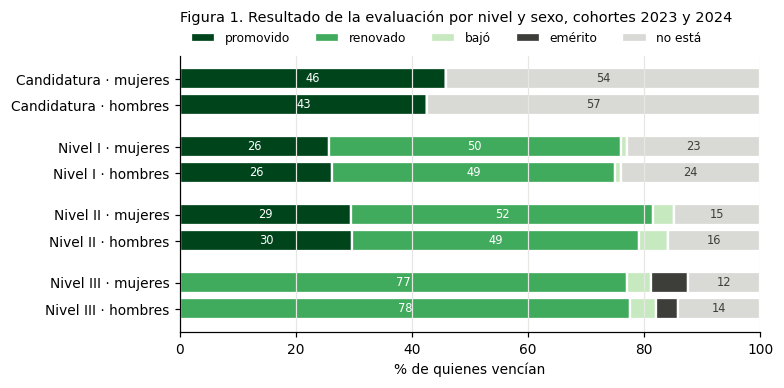

In [5]:
ORD = ["promovido", "renovado", "bajó", "emérito", "no está"]
TONOS = {"promovido": "#00441b", "renovado": "#41ab5d", "bajó": "#c7e9c0", "emérito": "#3d3d3a", "no está": "#d9d9d6"}
niveles = ["Candidatura", "Nivel I", "Nivel II", "Nivel III"]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
y, etiquetas = 0, []
for nv in niveles:
    for s in ("M", "H"):
        g = ev[(ev["nivel_txt"] == nv) & (ev["sexo"] == s)]
        izq = 0
        for r in ORD:
            w = 100 * (g["resultado"] == r).mean()
            ax.barh(y, w, left=izq, color=TONOS[r], edgecolor="white", linewidth=1.5, height=0.8,
                    label=r if (nv, s) == ("Nivel III", "M") else None)
            if w >= 7:
                ax.text(izq + w / 2, y, f"{w:.0f}", ha="center", va="center", fontsize=7.5,
                        color="white" if r in ("promovido", "renovado", "emérito") else OSCURO)
            izq += w
        etiquetas.append((y, f"{nv} · {'mujeres' if s == 'M' else 'hombres'}"))
        y -= 1
    y -= 0.6
ax.set_yticks([e[0] for e in etiquetas], [e[1] for e in etiquetas])
ax.set_xlim(0, 100); ax.set_xlabel("% de quienes vencían"); ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=8)
ax.set_title("Figura 1. Resultado de la evaluación por nivel y sexo, cohortes 2023 y 2024", loc="left", pad=22, fontsize=9.5)
plt.tight_layout(); plt.show()

Las dos barras de cada nivel son casi iguales. La diferencia más visible está en Candidatura: el 46 % de las candidatas pasa a nivel I, contra el 43 % de los candidatos.

## Diferencias con controles

Efecto de ser mujer en puntos porcentuales, con efectos fijos de nivel, área y año. Cada fila se estima también sin las 189 personas con sexo del diccionario.

In [6]:
filas = []
sigue = ev[(ev["resultado"] != "no está") & ev["nivel"].isin(["1", "2"])]
casos = [("Sigue en el SNII | vencía", ev, P.SIGUE),
         ("Promovido | sigue (I y II)", sigue, "promovido"),
         ("Promovido | vencía (C, I, II)", ev[ev["nivel"].isin(["C", "1", "2"])], "promovido"),
         ("Prorrogado | vencía", v, "prorrogado")]
for nom, base, y in casos:
    for et, b in [("todas", base), ("sexo por grado", base[base["sexo_fuente"] == "grado"])]:
        r = P.logit(b, y)
        filas.append({"resultado": nom, "muestra": et, "n": r["n"], "dif (pp)": r["dif_pp"],
                      "IC 95 %": f"[{r['dif_lo']:+.1f}, {r['dif_hi']:+.1f}]", "OR": r["OR"], "p": r["p"]})
dif = pd.DataFrame(filas); dif.round(3)

,resultado,muestra,n,dif (pp),IC 95 %,OR,p
0,Sigue en el SNII | vencía,todas,12841,2.237,"[+0.6, +3.8]",1.125,0.006
1,Sigue en el SNII | vencía,sexo por grado,12623,1.815,"[+0.2, +3.4]",1.102,0.026
2,Promovido | sigue (I y II),todas,6859,-0.478,"[-2.9, +1.9]",0.979,0.693
3,Promovido | sigue (I y II),sexo por grado,6778,-0.543,"[-2.9, +1.9]",0.976,0.657
4,"Promovido | vencía (C, I, II)",todas,12405,0.786,"[-0.9, +2.5]",1.038,0.359
5,"Promovido | vencía (C, I, II)",sexo por grado,12192,0.645,"[-1.1, +2.3]",1.031,0.458
6,Prorrogado | vencía,todas,16993,2.636,"[+1.4, +3.9]",1.183,0.000
7,Prorrogado | vencía,sexo por grado,16731,2.591,"[+1.3, +3.9]",1.179,0.000


- **Seguir en el SNII:** las mujeres siguen un poco **más** que los hombres, +2.2 pp (+1.8 pp sin el diccionario). La diferencia es pequeña pero no es cero.
- **Promoción:** entre quienes siguen en nivel I o II, la diferencia es −0.5 pp [−2.9, +1.9]: no se distingue de cero, y el intervalo descarta diferencias mayores a 3 pp en cualquier dirección.
- **Prórrogas:** las mujeres reciben más, +2.6 pp. En nivel III, el 18 % de las mujeres que vencían recibió prórroga contra el 9 % de los hombres (tabla siguiente). El padrón no dice el motivo. Una hipótesis compatible, pero no verificada, son las extensiones por maternidad o cuidados que prevé el reglamento.

In [7]:
P.tasas(v, ["nivel_txt"], "prorrogado").assign(sexo=lambda x: x["sexo"].map({"M": "mujeres", "H": "hombres"})).round(1)

,nivel_txt,sexo,n,k,pct,lo,hi
0,Candidatura,hombres,1978,55,2.8,2.1,3.6
1,Candidatura,mujeres,1727,81,4.7,3.8,5.8
2,Nivel I,hombres,6414,1902,29.7,28.5,30.8
3,Nivel I,mujeres,4166,1344,32.3,30.9,33.7
4,Nivel II,hombres,1410,223,15.8,14.0,17.8
5,Nivel II,mujeres,699,137,19.6,16.8,22.7
6,Nivel III,hombres,422,39,9.2,6.8,12.4
7,Nivel III,mujeres,148,26,17.6,12.3,24.5


## Por área

Misma diferencia (pp), con efectos fijos de nivel y año, por área del conocimiento del padrón de *t*.

In [8]:
CORTO = {"Biología y Química": "Biología y Química", "Ciencias Sociales": "Ciencias Sociales",
         "Ciencias de Agricultura, Agropecuarias, Forestales y de Ecosistemas": "Agropecuarias y Forestales",
         "Ciencias de la Conducta y la Educación": "Conducta y Educación",
         "Físico-Matemáticas y Ciencias de la Tierra": "Físico-Matemáticas",
         "Humanidades": "Humanidades", "Ingenierías y Desarrollo Tecnológico": "Ingenierías",
         "Interdisciplinaria": "Interdisciplinaria", "Medicina y Ciencias de la Salud": "Medicina y Salud"}
a = P.por_area(d).sort_values("%M").assign(area=lambda x: x["area"].map(CORTO).fillna(x["area"]))
f = lambda c: a.apply(lambda r: f"{r[c + '_dif']:+.1f} [{r[c + '_lo']:+.1f}, {r[c + '_hi']:+.1f}]"
                     if pd.notna(r[c + "_lo"]) else "n.d.", axis=1)
pd.DataFrame({"área": a["area"], "n": a["n"], "%M": a["%M"].round(0).astype(int),
              "sigue, pp": f("sigue"), "promovido, pp": f("promo")}).set_index("área")

,n,%M,"sigue, pp","promovido, pp"
área,,,,
Ingenierías,1840,23,"+5.0 [+0.3, +9.7]","+0.7 [-6.0, +7.3]"
Físico-Matemáticas,1804,24,"+0.8 [-3.7, +5.2]","-5.3 [-12.6, +2.1]"
Interdisciplinaria,29,31,"+42.4 [+8.9, +75.8]",n.d.
Agropecuarias y Forestales,1629,38,"-0.7 [-4.9, +3.6]","+4.3 [-2.5, +11.1]"
Ciencias Sociales,2083,43,"+2.5 [-1.4, +6.4]","-0.3 [-6.2, +5.6]"
Biología y Química,2181,46,"-0.2 [-3.8, +3.4]","-1.3 [-6.7, +4.1]"
Humanidades,1670,50,"+1.4 [-2.8, +5.6]","-2.3 [-8.8, +4.2]"
Medicina y Salud,1522,51,"+7.0 [+2.4, +11.6]","+2.0 [-4.1, +8.1]"
Conducta y Educación,83,52,"+21.6 [+5.4, +37.8]",n.d.


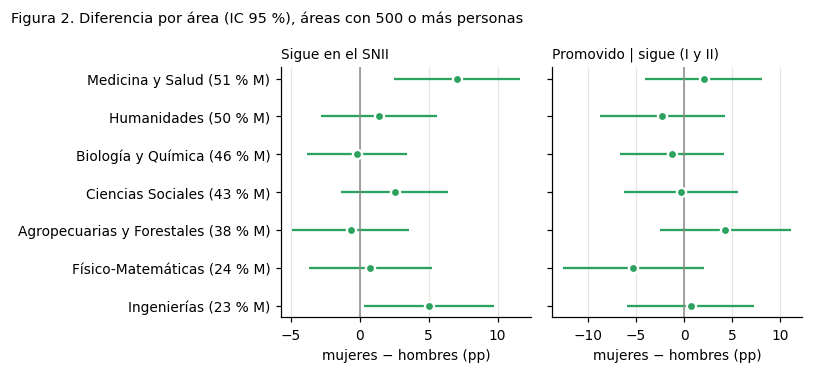

In [9]:
a2 = a[a["n"] >= 500].reset_index(drop=True)
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.4), sharey=True)
for ax, (c, tit) in zip(axs, [("sigue", "Sigue en el SNII"), ("promo", "Promovido | sigue (I y II)")]):
    yy = np.arange(len(a2))
    ax.errorbar(a2[f"{c}_dif"], yy, xerr=[a2[f"{c}_dif"] - a2[f"{c}_lo"], a2[f"{c}_hi"] - a2[f"{c}_dif"]],
                fmt="o", color=COLOR["M"], ecolor=COLOR["M"], ms=6, capsize=0, lw=1.5,
                mec="white", mew=1.5)
    ax.axvline(0, color=GRIS, lw=1); ax.set_title(tit, loc="left", fontsize=9)
    ax.set_xlabel("mujeres − hombres (pp)"); ax.grid(axis="y", visible=False)
axs[0].set_yticks(yy, [f"{r.area} ({r['%M']:.0f} % M)" for _, r in a2.iterrows()])
fig.suptitle("Figura 2. Diferencia por área (IC 95 %), áreas con 500 o más personas", x=0.01, ha="left", fontsize=9.5)
plt.tight_layout(); plt.show()

Ningún área muestra una desventaja significativa de las mujeres. Las diferencias positivas en Medicina y en Ingenierías (seguir en el SNII) son las que empujan el promedio. Ciencias de la Conducta e Interdisciplinaria tienen menos de 100 personas en las cohortes porque la taxonomía de áreas cambió en 2023; no se grafican.

## Otras comprobaciones

In [10]:
ne = v[(v["anio"] == 2023) & (v["resultado"] == "no está")]
vuelve = ne.assign(vuelve=ne["CVU"].isin(padrones[2025]["CVU"])).groupby("sexo")["vuelve"].agg(["size", "mean"])
vuelve["mean"] *= 100
print("De quienes vencían en 2023 y no están en 2024, % que reaparece en 2025:")
print(vuelve.rename(columns={"size": "n", "mean": "% vuelve"}).round(1))
print("\nPromoción anticipada: vigentes que NO vencían y aparecen promovidos al año siguiente")
print(P.anticipada(d).round(2).to_string(index=False))

De quienes vencían en 2023 y no están en 2024, % que reaparece en 2025:
        n  % vuelve
sexo               
H     780      14.1
M     527      13.1

Promoción anticipada: vigentes que NO vencían y aparecen promovidos al año siguiente
  nivel_txt sexo     n  k  pct   lo   hi
Candidatura    H  8818 14 0.16 0.09 0.27
Candidatura    M  7949 10 0.13 0.07 0.23
    Nivel I    H 21616 23 0.11 0.07 0.16
    Nivel I    M 14440  8 0.06 0.03 0.11
   Nivel II    H  6324 11 0.17 0.10 0.31
   Nivel II    M  3453  7 0.20 0.10 0.42


- La reaparición al año siguiente (reconsideraciones o solicitudes de reingreso) es igual por sexo, alrededor del 13–14 %.
- La promoción anticipada casi no existe en los padrones (0.1 %): las promociones se dan al vencer la vigencia, así que las cohortes de vencimiento las capturan casi todas.

## Lectura de los resultados

- **En la evaluación de permanencia y promoción, no hay desventaja de las mujeres.** A igual nivel, área y año, las mujeres que vencen siguen en el SNII un poco más que los hombres (+2 pp) y se promueven igual (diferencia menor a 1 pp, no significativa).
- Esto es coherente con los reportes de las universidades: la brecha no está en el trato a igual posición, sino en **quién llega** a cada nivel.
- **La segregación por nivel del SNII**, por tanto, no se explica por cómo se evalúa a quienes ya están dentro. Las causas posibles son anteriores: quién ingresa, quién solicita promoción (aquí no se ve) y la composición histórica del padrón (efecto de cohorte).
- **Las prórrogas** son la única diferencia clara, y van a favor de las mujeres en el sentido de que extienden su vigencia sin evaluación. Pero también retrasan la promoción: si una prórroga es por cuidados, la mujer llega más tarde a la siguiente evaluación. Medir ese retraso necesita más años de panel.

## Limitaciones

1. **«No está» mezcla rechazos con quien no solicitó** (jubilación, salida del país, muerte, cambio de carrera). Si las mujeres solicitan menos y se rechazan menos, o al revés, el padrón no puede distinguirlo.
2. **No se ve quién pidió promoción.** «Renovado» incluye a quien pidió subir y no lo logró y a quien solo pidió permanencia. La tasa de promoción es del total que vencía, no de quienes la solicitaron.
3. **Solo dos convocatorias** (2023 y 2024), con un reglamento nuevo en 2023. Los padrones anteriores a 2023 no traen CVU en todos los años, y algunos años no traen fechas de vigencia: extender la serie hacia atrás requiere enlazar por nombre.
4. **Ingreso de personas nuevas:** no se puede medir sin la lista de solicitantes. Es la pregunta que queda para una solicitud de información a la SECIHTI (solicitudes y aprobaciones por convocatoria, sexo, área y tipo de solicitud).
5. **Sexo:** viene del grado académico en el padrón 2023 (DR. / DRA.), que es autodeclarado en el CVU pero no es un campo de sexo; 1.5 % de las cohortes usa el diccionario de nombres, y los resultados no cambian sin ellas.
6. **Prórrogas:** el motivo no está en el padrón.

## Próximos pasos

- Repetir con la cohorte que vence en 2025 cuando salga el padrón 2026.
- Extender hacia atrás (2015–2022) enlazando por nombre, para tener más convocatorias y medir el retraso por prórroga.
- Cruzar con las universidades del proyecto `uni`: ¿la permanencia en el SNII difiere entre las académicas de las UPE y las de otras instituciones?
- Solicitud a la SECIHTI: solicitudes de ingreso y aprobaciones por convocatoria, sexo, área y tipo de solicitud.